# TrafficFlowBench 2026 데이터 탐색 (EDA)

이 노트북은 **처음 데이터를 보는 사람**을 위한 안내서입니다. 파일 구조 → 관측치 → 결측과 정답 대상 → 시간·공간 패턴 → Task 2/4 입력 순서로 살펴봅니다. 기본값은 `D7_I10_E` 패널이며, 일별·주별 자료만 읽어 메모리 사용을 제한합니다. 출력 아래의 수치는 이 폴더에 있는 릴리스에서 직접 계산합니다.

**실행 환경**: `conda activate easypj` 후 Jupyter에서 이 파일을 열어 순서대로 실행하세요. 필요한 Python 패키지는 `polars`, `numpy`, `matplotlib`, `IPython`입니다. GPU는 사용하지 않습니다. 기본 데이터 위치는 `Traffic/data/kaggle_public`; 다른 곳이면 `TFB_DATA_ROOT` 환경변수를 설정합니다.

**읽는 법**: 패널은 한 도로 회랑의 한 방향입니다. 본선 검지기 관측은 5분 간격입니다. 시간은 합성 캘린더이며 실제 2030~2031년의 교통 사건을 뜻하지 않습니다.

In [1]:
from pathlib import Path
from datetime import datetime
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.22})

def find_data_root():
    if os.environ.get("TFB_DATA_ROOT"):
        root = Path(os.environ["TFB_DATA_ROOT"]).expanduser().resolve()
        if not (root / "config" / "competition_contract.json").exists():
            raise FileNotFoundError(f"TFB_DATA_ROOT is not a release directory: {root}")
        return root
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base / "data" / "kaggle_public", base / "Traffic" / "data" / "kaggle_public"):
            if (candidate / "config" / "competition_contract.json").exists():
                return candidate.resolve()
    raise FileNotFoundError("Traffic/data/kaggle_public not found. Set TFB_DATA_ROOT.")

DATA = find_data_root()
PANEL = "D7_I10_E"  # 다른 패널로 바꿔 다시 실행 가능
PANELS = sorted(p.name for p in (DATA / "corridors").iterdir() if p.is_dir())
assert PANEL in PANELS, f"Unknown panel: {PANEL}"
QUEUE_PANEL = PANEL if (DATA / "task2" / PANEL).exists() else "D7_I10_E"
TASK_SPLIT = "validation"
print("Data:", DATA)
print("Panel:", PANEL, "| Task 2 example:", QUEUE_PANEL, "| held-out input:", TASK_SPLIT)
print("Polars:", pl.__version__)

Data: data/kaggle_public (local)
Panel: D7_I10_E | Task 2 example: D7_I10_E | held-out input: validation
Polars: 1.41.1


## 1. 데이터 지도와 문제 정의

| 경로 | 내용 | 정답 공개 여부 |
|---|---|---|
| `corridors/<panel>/network/` | 링크, 차로수, 제한 속도, 연결·경로 구조 | 입력 |
| `corridors/<panel>/train/mainline_states/` | 마스킹 전 본선 관측 | **train만 공개**; Task 1 로컬 평가에 사용 |
| `corridors/<panel>/<split>/mainline_states_masked/` | 일부 속도·유량을 비운 본선 관측 | train/validation/private 입력 |
| `corridors/<panel>/<split>/ramp_states/` | 진입·진출 램프 유량과 품질 | 입력 |
| `task1/<panel>/<split>/sample_submission_state.csv` | **정확한** 상태 복원 대상 목록 | 채워야 할 위치만 공개 |
| `task2/<panel>/<split>/` | 60분 이력, 30분 예측 위치 | 실제 queue 라벨 비공개 |
| `task4/<panel>/<split>/` | 링크 카운트, 약한 경로 유량 prior, 예측 위치 | 기준 path flow 비공개 |
| `sample_submission.csv` | 최종 업로드 형식 | 0은 빈 템플릿 값 |
| `submission_key.csv` | `submission_id` ↔ 예측 위치 매핑 | 읽기 전용; 업로드 대상 아님 |

**단일 제출 파일**의 `state` 행은 Task 1(속도·유량)과 Task 3(물리 정합성)에 사용되고, `queue` 행은 Task 2, `odme` 행은 Task 4에 사용됩니다. Task 3 전용 제출 행은 없습니다.

파일 메타데이터 기준 본선 관측 규모는 train 원본 124,461,792행 + masked 124,461,792행, validation masked 14,133,024행, private masked 13,677,120행입니다. 램프 관측은 각각 76,422,528 / 8,678,016 / 8,398,080행입니다. 한 번에 전부 읽기보다 패널·기간을 선택해 탐색해야 합니다.

In [2]:
contract = json.loads((DATA / "config" / "competition_contract.json").read_text())
files = [p for p in DATA.rglob("*") if p.is_file()]
print(f"Release: {len(files):,} files, {sum(p.stat().st_size for p in files)/1e9:.2f} GB (decimal)")
print("Panels:", ", ".join(PANELS))
display(pl.DataFrame([
    {"split": split, "period": f"{info['start']} ~ {info['end']}", "days": info['days'], "labels": info['labels']}
    for split, info in contract["split"].items() if isinstance(info, dict)
]))
display(pl.DataFrame([
    {"score_component": task, "weight": weight}
    for task, weight in contract["overall_score"]["task_weights"].items()
]))

Release: 9,688 files, 12.39 GB (decimal)
Panels: D12_I405_N, D12_I405_S, D12_I5_N, D12_I5_S, D7_I10_E, D7_I10_W, D7_I210_E, D7_I210_W, D7_I405_N, D7_I405_S


split,period,days,labels
str,str,i64,str
"""train""","""2030-06-01 ~ 2031-02-28""",273,"""released"""
"""validation""","""2031-03-01 ~ 2031-03-31""",31,"""hidden"""
"""private""","""2031-04-01 ~ 2031-04-30""",30,"""hidden"""


score_component,weight
str,f64
"""state""",0.35
"""queue""",0.3
"""physics""",0.15
"""odme""",0.2


### 실제 제출 행 수

`submission_key.csv`는 약 643 MB입니다. 아래는 Polars의 lazy CSV 스캔에서 세 열만 읽어 집계합니다. `train`은 최종 업로드에 포함되지 않습니다. 행마다 식별자가 있으며, `sample_submission.csv`의 0은 정답이 아닙니다.

In [3]:
key_scan = pl.scan_csv(DATA / "submission_key.csv")
submission_counts = (
    key_scan.select("split", "task")
    .group_by("split", "task")
    .agg(pl.len().alias("rows"))
    .sort("split", "task")
    .collect(engine="streaming")
)
display(submission_counts)
print("Total rows:", f"{submission_counts['rows'].sum():,}")
print("Upload columns:", pl.scan_csv(DATA / "sample_submission.csv").collect_schema().names())

split,task,rows
str,str,u32
"""private""","""odme""",35354
"""private""","""queue""",87000
"""private""","""state""",3284419
"""validation""","""odme""",35354
"""validation""","""queue""",87000
"""validation""","""state""",3451376


Total rows: 6,980,503
Upload columns: ['submission_id', 'task', 'speed_kmh', 'flow_vph', 'queue_pred', 'path_flow']


`submission_id` 자체에는 도로 정보가 들어 있지 않습니다. 아래처럼 `submission_key.csv`를 보면 각 ID가 어느 split·패널·시각·링크/경로를 가리키는지 알 수 있습니다. `sample_submission.csv`의 예측 열은 모두 초기값 0입니다.

In [4]:
key_examples = pl.concat([
    key_scan.filter(pl.col("task") == task).head(1).collect()
    for task in ("state", "queue", "odme")
])
display(key_examples.select("submission_id", "task", "split", "panel", "timestamp", "link_id", "window_id", "departure_time", "path_id"))
display(pl.scan_csv(DATA / "sample_submission.csv")
        .filter(pl.col("submission_id").is_in(key_examples["submission_id"].to_list()))
        .collect())

submission_id,task,split,panel,timestamp,link_id,window_id,departure_time,path_id
i64,str,str,str,str,str,str,str,str
1,"""state""","""validation""","""D12_I405_N""","""2031-03-01T00:00:00Z""","""L405N-010""","""-""",null,"""-"""
6735796,"""queue""","""validation""","""D12_I5_N""","""2031-03-01T11:45:00Z""","""L5N-001""","""Q2_D12_I5_N_validation_001""",null,"""-"""
6909796,"""odme""","""validation""","""D12_I405_N""",null,null,"""-""","""SYN_PM_VALIDATION""","""P000_001"""


submission_id,task,speed_kmh,flow_vph,queue_pred,path_flow
i64,str,i64,i64,i64,i64
1,"""state""",0,0,0,0
6735796,"""queue""",0,0,0,0
6909796,"""odme""",0,0,0,0


## 2. 한 행이 뜻하는 것

본선 행은 `(timestamp, station_id, link_id)`의 **한 검지기·한 링크·5분 구간**입니다. `speed_kmh`는 속도, `flow_vph`는 시간당 환산 유량입니다. `pct_observed`는 그 5분 중 실제로 관측된 비율입니다. `is_score_eligible=1`은 원본 관측이 품질 기준(`pct_observed >= 75` 및 필요한 측정값 존재)을 통과했다는 뜻입니다. 마스킹 후에는 이 플래그가 1이어도 속도·유량 열이 비어 있을 수 있습니다.

`occupancy`와 `density_occ_linear_vehpkm`은 참고 채널입니다. Task 3의 density는 이 열 대신 **`flow_vph / speed_kmh`**로 유도합니다. 램프 행에는 `flow_vph`만 있고 속도는 없습니다.

In [5]:
network = DATA / "corridors" / PANEL / "network"
links = pl.read_csv(network / "links.csv")
topology = pl.read_csv(network / "lwr_mainline_topology.csv")
train_root = DATA / "corridors" / PANEL / "train"
masked_files = sorted((train_root / "mainline_states_masked").rglob("*.parquet"))
day_file = masked_files[0]
day = day_file.stem.removeprefix("synthetic_mainline_").replace("_", "-")
unmasked_file = train_root / "mainline_states" / f"year_month={day[:7]}" / day_file.name
masked = pl.read_parquet(day_file)
unmasked = pl.read_parquet(unmasked_file)
print("Example day:", day, "| masking regime:", masked["mask_regime"][0])
print("Unmasked shape:", unmasked.shape, "| masked shape:", masked.shape)
print("Mainline columns:", unmasked.columns)
display(unmasked.select("timestamp", "station_id", "link_id", "milepost", "speed_kmh", "flow_vph", "pct_observed", "is_score_eligible").head(5))
print("Link schema:", links.schema)
display(links.head(5))

Example day: 2030-06-03 | masking regime: R1
Unmasked shape: (42048, 16) | masked shape: (42048, 17)
Mainline columns: ['corridor_id', 'date', 'timestamp', 'station_id', 'link_id', 'milepost', 'direction', 'speed_kmh', 'flow_vph', 'occupancy', 'density_occ_linear_vehpkm', 'pct_observed', 'is_observed', 'is_imputed', 'is_score_eligible', 'is_missing']


timestamp,station_id,link_id,milepost,speed_kmh,flow_vph,pct_observed,is_score_eligible
str,str,str,f64,f64,f64,i64,i64
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0127""","""L10E-002""",42.347,112.896004,2419.342672,100,1
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0109""","""L10E-008""",33.828,106.256977,2485.23377,100,1
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0078""","""L10E-012""",18.996,101.2,2582.385977,100,1
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0072""","""L10E-014""",17.001,116.467401,2531.67663,100,1
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0074""","""L10E-017""",17.733,null,null,0,0


Link schema: Schema([('link_id', String), ('length_km', Float64), ('lanes', Float64), ('free_speed_kmh', Float64), ('capacity_vph', Float64)])


link_id,length_km,lanes,free_speed_kmh,capacity_vph
str,f64,f64,f64,f64
"""L10E-166""",0.414,3.0,105.4,5756.4
"""L10E-147""",0.448,3.0,105.4,5756.4
"""L10E-209""",1.424,3.0,105.4,5756.4
"""L10E-171""",0.12,3.0,113.0,5756.4
"""L10E-043""",0.041,4.0,113.0,7675.2


In [6]:
ramp_file = sorted((train_root / "ramp_states").rglob(f"*{day.replace('-', '_')}.parquet"))[0]
ramp = pl.read_parquet(ramp_file)
print("Ramp shape:", ramp.shape, "| columns:", ramp.columns)
display(ramp.select("timestamp", "ramp_link_id", "ramp_type", "flow_vph", "pct_observed", "is_score_eligible").head(5))
print("Ramp type counts:")
display(ramp.group_by("ramp_type").agg(pl.len().alias("rows")).sort("ramp_type"))

Ramp shape: (33408, 12) | columns: ['corridor_id', 'date', 'timestamp', 'station_id', 'ramp_link_id', 'ramp_type', 'flow_vph', 'pct_observed', 'is_observed', 'is_imputed', 'is_score_eligible', 'is_missing']


timestamp,ramp_link_id,ramp_type,flow_vph,pct_observed,is_score_eligible
str,str,str,f64,i64,i64
"""2030-06-03T00:00:00Z""","""SYN_RAMP_D7_I10_E_0001""","""OR""",7.9618,50,0
"""2030-06-03T00:00:00Z""","""SYN_RAMP_D7_I10_E_0002""","""OR""",0.160683,100,1
"""2030-06-03T00:00:00Z""","""SYN_RAMP_D7_I10_E_0003""","""OR""",19.632554,100,1
"""2030-06-03T00:00:00Z""","""SYN_RAMP_D7_I10_E_0004""","""OR""",null,0,0
"""2030-06-03T00:00:00Z""","""SYN_RAMP_D7_I10_E_0005""","""OR""",23.763406,100,1


Ramp type counts:


ramp_type,rows
str,u32
"""FR""",15552
"""OR""",17856


## 3. 결측과 Task 1 타깃은 다릅니다

센서가 관측하지 못한 셀에는 측정 채널이 원래 비어 있을 수 있습니다. 마스킹은 관측 가능한 셀의 `speed_kmh`, `flow_vph`, `occupancy`, `density_occ_linear_vehpkm`을 함께 비웁니다. 품질 열은 남습니다. 또한 Task 2 예측 기간과 버퍼의 blank도 있으므로, **빈 속도값 전체를 Task 1 타깃으로 간주하면 안 됩니다.** 타깃은 항상 `task1/.../sample_submission_state.csv`에서 읽습니다.

아래 예제는 같은 날짜의 마스킹 전후 행을 결합합니다. train에서만 가능한 비교입니다.

In [7]:
JOIN = ["timestamp", "station_id", "link_id"]
target_file = DATA / "task1" / PANEL / "train" / "sample_submission_state.csv"
targets_day = (
    pl.scan_csv(target_file)
    .filter(pl.col("timestamp").str.starts_with(day))
    .select(JOIN)
    .collect()
    .with_columns(pl.lit(True).alias("task1_target"))
)
check = (
    masked.join(unmasked.select(JOIN + ["speed_kmh", "flow_vph"]), on=JOIN, how="left", suffix="_unmasked")
    .join(targets_day, on=JOIN, how="left")
    .with_columns(pl.col("task1_target").fill_null(False))
)
quality_summary = pl.DataFrame([{
    "all_cells": check.height,
    "eligible": check.filter(pl.col("is_score_eligible") == 1).height,
    "raw_speed_null": check.filter(pl.col("speed_kmh_unmasked").is_null()).height,
    "masked_speed_null": check.filter(pl.col("speed_kmh").is_null()).height,
    "task1_targets": check.filter(pl.col("task1_target")).height,
    "blank_but_not_target": check.filter(pl.col("speed_kmh").is_null() & ~pl.col("task1_target")).height,
}])
display(quality_summary)
display(check.filter(pl.col("task1_target")).select(JOIN + ["mask_regime", "pct_observed", "speed_kmh", "speed_kmh_unmasked", "flow_vph", "flow_vph_unmasked"]).head(5))

all_cells,eligible,raw_speed_null,masked_speed_null,task1_targets,blank_but_not_target
i64,i64,i64,i64,i64,i64
42048,32048,7023,12685,5662,7023


timestamp,station_id,link_id,mask_regime,pct_observed,speed_kmh,speed_kmh_unmasked,flow_vph,flow_vph_unmasked
str,str,str,str,i64,f64,f64,f64,f64
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0109""","""L10E-008""","""R1""",100,null,106.256977,null,2485.23377
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0057""","""L10E-027""","""R1""",100,null,116.242339,null,2633.376088
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0088""","""L10E-083""","""R1""",100,null,113.092778,null,2567.898527
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0086""","""L10E-084""","""R1""",100,null,113.487638,null,2511.222451
"""2030-06-03T00:00:00Z""","""SYN_D7_I10_E_0033""","""L10E-088""","""R1""",100,null,113.995957,null,2619.205332


### R1 / R2 / R3의 마스킹 강도

각 날짜는 레짐 하나에만 속합니다. 다음은 같은 패널에서 레짐별 **하루씩** 뽑은 관찰 예시입니다. R1/R2/R3은 점점 더 많은 적격 관측을 가립니다. 표시 비율은 하루 표본이므로 릴리스 전체 비율과 정확히 같을 필요는 없습니다.

regime,sample_day,eligible_cells,eligible_blank_pct,task1_target_pct
str,str,i64,f64,f64
"""R1""","""2030-06-03""",32048,17.667249,17.667249
"""R2""","""2030-06-01""",31823,27.137605,27.137605
"""R3""","""2030-06-06""",31955,49.773118,49.773118


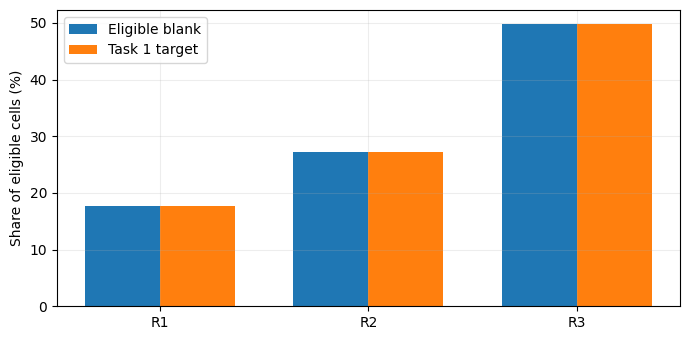

In [8]:
regime_rows = []
for regime in ("R1", "R2", "R3"):
    f = sorted((train_root / "mainline_states_masked" / f"mask_regime={regime}").glob("*.parquet"))[0]
    d = f.stem.removeprefix("synthetic_mainline_").replace("_", "-")
    df = pl.read_parquet(f, columns=["speed_kmh", "is_score_eligible"])
    eligible = df.filter(pl.col("is_score_eligible") == 1)
    target_n = pl.scan_csv(target_file).filter(pl.col("timestamp").str.starts_with(d)).select(pl.len()).collect().item()
    regime_rows.append({"regime": regime, "sample_day": d, "eligible_cells": eligible.height,
                        "eligible_blank_pct": 100 * eligible["speed_kmh"].is_null().sum() / eligible.height,
                        "task1_target_pct": 100 * target_n / eligible.height})
regime_summary = pl.DataFrame(regime_rows)
display(regime_summary)
fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(3)
ax.bar(x - 0.18, regime_summary["eligible_blank_pct"].to_numpy(), 0.36, label="Eligible blank")
ax.bar(x + 0.18, regime_summary["task1_target_pct"].to_numpy(), 0.36, label="Task 1 target")
ax.set_xticks(x, regime_summary["regime"].to_list())
ax.set_ylabel("Share of eligible cells (%)")
ax.legend()
plt.tight_layout(); plt.show()

### 품질을 먼저 확인하기

`pct_observed=0` 또는 75 미만인 램프 유량은 **0대/시 관측**이 아닙니다. 센서 증거가 부족하다는 뜻이므로 램프 결측을 유량 0으로 대체해 물리 보존식을 계산하면 왜곡됩니다. 아래는 예시 하루의 품질 분포입니다.

source,0%,1-74%,75-99%,100%
str,i64,i64,i64,i64
"""mainline""",7023,2977,5354,26694
"""ramp""",6885,1339,0,25184


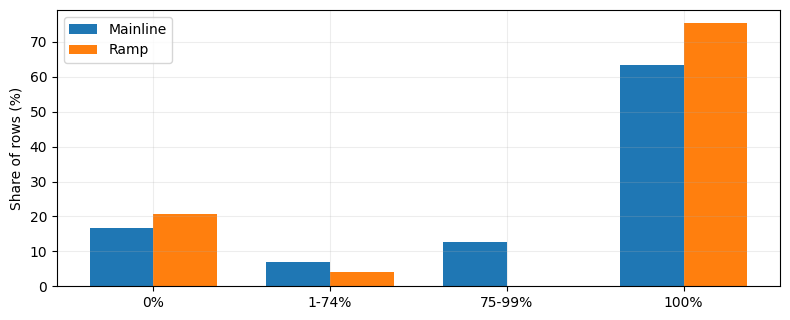

In [9]:
def quality_bins(df):
    return {
        "0%": df.filter(pl.col("pct_observed") == 0).height,
        "1-74%": df.filter((pl.col("pct_observed") > 0) & (pl.col("pct_observed") < 75)).height,
        "75-99%": df.filter((pl.col("pct_observed") >= 75) & (pl.col("pct_observed") < 100)).height,
        "100%": df.filter(pl.col("pct_observed") == 100).height,
    }
main_q, ramp_q = quality_bins(unmasked), quality_bins(ramp)
display(pl.DataFrame([{"source": "mainline", **main_q}, {"source": "ramp", **ramp_q}]))
fig, ax = plt.subplots(figsize=(8, 3.3))
labels = list(main_q)
x = np.arange(len(labels))
ax.bar(x - .18, [main_q[k]/unmasked.height*100 for k in labels], .36, label="Mainline")
ax.bar(x + .18, [ramp_q[k]/ramp.height*100 for k in labels], .36, label="Ramp")
ax.set_xticks(x, labels); ax.set_ylabel("Share of rows (%)"); ax.legend()
plt.tight_layout(); plt.show()

## 4. 한 패널의 시간·공간 패턴

다음 집계는 train 첫 7일의 마스킹 **전** 본선 관측 중 적격 행만 사용합니다. 전월/전패널을 읽지 않고 lazy 집계합니다. 유량은 차로수로 나누어 비교합니다. 그래프는 데이터 분포를 이해하기 위한 것이며, validation/private 정답을 보여주지 않습니다.

hour,n,mean_speed_kmh,mean_flow_per_lane
i8,u32,f64,f64
0,9405,112.598334,561.024898
1,9449,112.571392,401.762288
2,9373,112.581921,321.064254
3,9326,112.520732,293.624644
4,9433,112.526392,365.080424
…,…,…,…
19,9391,98.707007,1300.463924
20,9435,105.694108,1218.872749
21,9314,111.416333,1051.408937


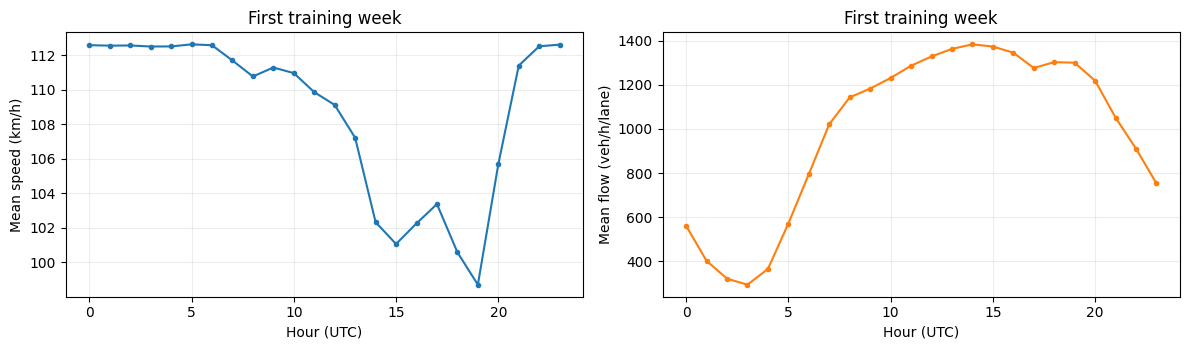

In [10]:
first_week = (
    pl.scan_parquet(train_root / "mainline_states" / "year_month=2030-06" / "*.parquet")
    .filter(pl.col("date") <= "2030-06-07")
    .filter(pl.col("is_score_eligible") == 1)
    .select("timestamp", "link_id", "speed_kmh", "flow_vph")
    .join(links.lazy().select("link_id", "lanes"), on="link_id", how="left")
    .with_columns(pl.col("timestamp").str.slice(11, 2).cast(pl.Int8).alias("hour"),
                  (pl.col("flow_vph") / pl.col("lanes")).alias("flow_per_lane"))
)
hourly = first_week.group_by("hour").agg(
    pl.len().alias("n"), pl.col("speed_kmh").mean().alias("mean_speed_kmh"),
    pl.col("flow_per_lane").mean().alias("mean_flow_per_lane")
).sort("hour").collect(engine="streaming")
display(hourly)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(hourly["hour"], hourly["mean_speed_kmh"], marker="o", ms=3)
axes[0].set(xlabel="Hour (UTC)", ylabel="Mean speed (km/h)", title="First training week")
axes[1].plot(hourly["hour"], hourly["mean_flow_per_lane"], marker="o", ms=3, color="tab:orange")
axes[1].set(xlabel="Hour (UTC)", ylabel="Mean flow (veh/h/lane)", title="First training week")
plt.tight_layout(); plt.show()

### 속도와 차로당 유량

한 날짜의 관측만 산점도로 봅니다. 혼잡에서는 속도와 유량 관계가 단순 직선이 아닐 수 있습니다. 결측과 품질 미달 관측은 제거합니다.

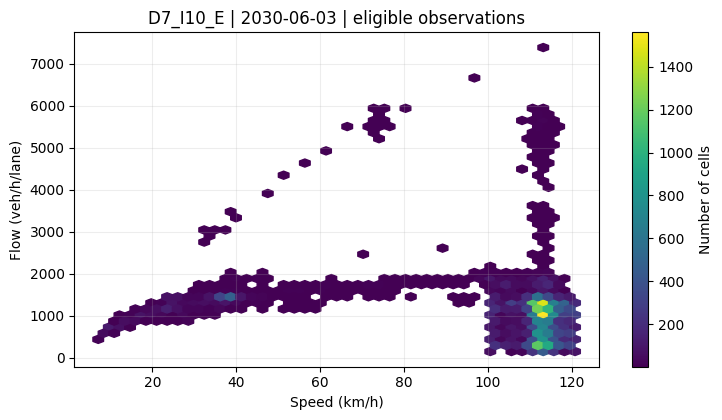

In [11]:
xy = (
    unmasked.filter(pl.col("is_score_eligible") == 1)
    .select("link_id", "speed_kmh", "flow_vph")
    .join(links.select("link_id", "lanes"), on="link_id")
    .with_columns((pl.col("flow_vph") / pl.col("lanes")).alias("flow_per_lane"))
    .drop_nulls(subset=["speed_kmh", "flow_per_lane"])
)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
hb = ax.hexbin(xy["speed_kmh"].to_numpy(), xy["flow_per_lane"].to_numpy(), gridsize=45, mincnt=1, cmap="viridis")
fig.colorbar(hb, ax=ax, label="Number of cells")
ax.set(xlabel="Speed (km/h)", ylabel="Flow (veh/h/lane)", title=f"{PANEL} | {day} | eligible observations")
plt.tight_layout(); plt.show()

### 링크 순서 × 시간 히트맵

`link_id` 문자열 또는 CSV 행 순서가 실제 도로 순서라고 가정하지 않습니다. `lwr_mainline_topology.csv`의 `order_index`로 링크를 정렬합니다. 왼쪽은 train의 마스킹 전 속도, 오른쪽은 입력으로 보이는 마스킹 후 속도입니다. 흰색은 결측입니다.

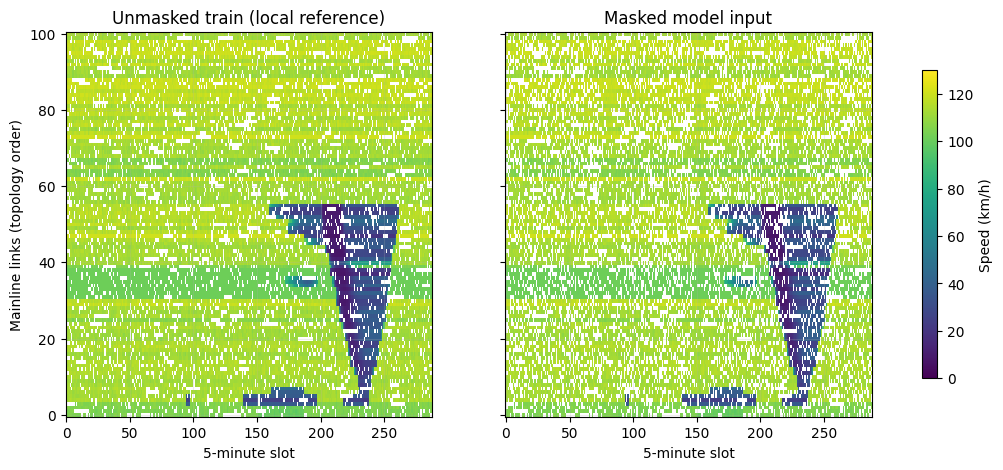

In [12]:
ordered_links = (
    topology.filter(pl.col("has_sensor") == 1)
    .select("link_id", "order_index")
    .unique(subset=["link_id"])
    .sort("order_index")["link_id"].to_list()
)
times = sorted(unmasked["timestamp"].unique().to_list())
link_ix = {v: i for i, v in enumerate(ordered_links)}
time_ix = {v: i for i, v in enumerate(times)}
def speed_matrix(df):
    matrix = np.full((len(ordered_links), len(times)), np.nan)
    for t, link, speed in df.select("timestamp", "link_id", "speed_kmh").iter_rows():
        if link in link_ix and speed is not None:
            matrix[link_ix[link], time_ix[t]] = speed
    return matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, frame, title in zip(axes, [unmasked, masked], ["Unmasked train (local reference)", "Masked model input"]):
    im = ax.imshow(speed_matrix(frame), aspect="auto", interpolation="nearest", origin="lower", vmin=0, vmax=130, cmap="viridis")
    ax.set(title=title, xlabel="5-minute slot")
axes[0].set_ylabel("Mainline links (topology order)")
fig.colorbar(im, ax=axes, label="Speed (km/h)", shrink=.8)
plt.show()

### 한 링크에서 실제로 가려진 값

파란 선은 train에서만 제공되는 마스킹 전 관측입니다. 검은 점은 모델 입력에 남아 있는 관측, 빨간 ×는 Task 1 공식 타깃 위치입니다. 이 그림의 빨간 위치에 대한 **정답을 볼 수 있는 것은 train뿐**입니다.

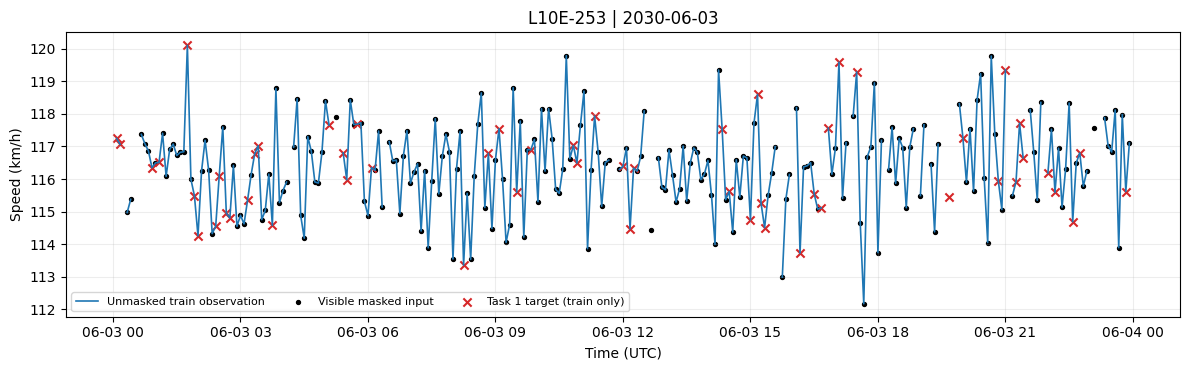

In [13]:
link_target_counts = check.filter(pl.col("task1_target")).group_by("link_id").agg(pl.len().alias("n")).sort("n", descending=True)
example_link = link_target_counts["link_id"][0]
series = check.filter(pl.col("link_id") == example_link).sort("timestamp")
dt = [datetime.fromisoformat(t.replace("Z", "+00:00")) for t in series["timestamp"]]
is_target = series["task1_target"].to_numpy()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(dt, series["speed_kmh_unmasked"].to_numpy(), lw=1.2, label="Unmasked train observation")
ax.scatter(dt, series["speed_kmh"].to_numpy(), s=8, color="black", label="Visible masked input")
ax.scatter(np.array(dt, dtype=object)[is_target], series.filter(pl.col("task1_target"))["speed_kmh_unmasked"].to_numpy(),
           s=35, marker="x", color="tab:red", label="Task 1 target (train only)")
ax.set(xlabel="Time (UTC)", ylabel="Speed (km/h)", title=f"{example_link} | {day}")
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

## 5. Task 2 — 60분을 보고 다음 30분 queue 예측

`window_index.csv`가 예측 시작점을 정의합니다. `window_history.parquet`에는 그 전 60분의 공개 관측이 있고, `sample_submission_queue.csv`는 이후 5분 간격 6스텝 × 링크별 제출 위치입니다. `queue_onset`과 `queue_ongoing` 조건이 있습니다. **실제 미래 queue 정답은 모든 split에서 비공개**입니다.

공식 queue는 숨겨진 underlying state의 속도가 자유 속도의 60% 이하인지로 정합니다. 공개 이력 속도에 같은 임계값을 그어 보는 것은 탐색용 근사입니다.

In [14]:
task2_dir = DATA / "task2" / QUEUE_PANEL / TASK_SPLIT
windows = pl.read_csv(task2_dir / "window_index.csv")
history = pl.read_parquet(task2_dir / "window_history.parquet")
queue_template = pl.read_csv(task2_dir / "sample_submission_queue.csv")
display(windows.group_by("condition").agg(pl.len().alias("windows")).sort("condition"))
display(windows.select("window_id", "condition", "history_start", "forecast_origin", "forecast_start", "forecast_end", "history_coverage").head(3))
print("History rows:", f"{history.height:,}", "| Queue template rows:", f"{queue_template.height:,}")
window = windows.row(0, named=True)
wid = window["window_id"]
q_cells = queue_template.filter(pl.col("window_id") == wid)
display(q_cells.group_by("timestamp").agg(pl.len().alias("links_to_predict")).sort("timestamp"))
actual_history_times = sorted(history.filter(pl.col("window_id") == wid)["timestamp"].unique().to_list())
print("Actual history:", len(actual_history_times), "timestamps,", actual_history_times[0], "to", actual_history_times[-1])
print("Index history_end:", window["history_end"], "| forecast origin:", window["forecast_origin"])

condition,windows
str,u32
"""queue_ongoing""",5
"""queue_onset""",5


window_id,condition,history_start,forecast_origin,forecast_start,forecast_end,history_coverage
str,str,str,str,str,str,f64
"""Q2_D7_I10_E_validation_001""","""queue_onset""","""2031-03-01T09:05:00Z""","""2031-03-01T10:05:00Z""","""2031-03-01T10:10:00Z""","""2031-03-01T10:35:00Z""",0.7494
"""Q2_D7_I10_E_validation_002""","""queue_onset""","""2031-03-02T11:25:00Z""","""2031-03-02T12:25:00Z""","""2031-03-02T12:30:00Z""","""2031-03-02T12:55:00Z""",0.7266
"""Q2_D7_I10_E_validation_003""","""queue_onset""","""2031-03-03T06:30:00Z""","""2031-03-03T07:30:00Z""","""2031-03-03T07:35:00Z""","""2031-03-03T08:00:00Z""",0.7517


History rows: 17,520 | Queue template rows: 8,760


timestamp,links_to_predict
str,u32
"""2031-03-01T10:10:00Z""",146
"""2031-03-01T10:15:00Z""",146
"""2031-03-01T10:20:00Z""",146
"""2031-03-01T10:25:00Z""",146
"""2031-03-01T10:30:00Z""",146
"""2031-03-01T10:35:00Z""",146


Actual history: 12 timestamps, 2031-03-01T09:05:00Z to 2031-03-01T10:00:00Z
Index history_end: 2031-03-01T10:05:00Z | forecast origin: 2031-03-01T10:05:00Z


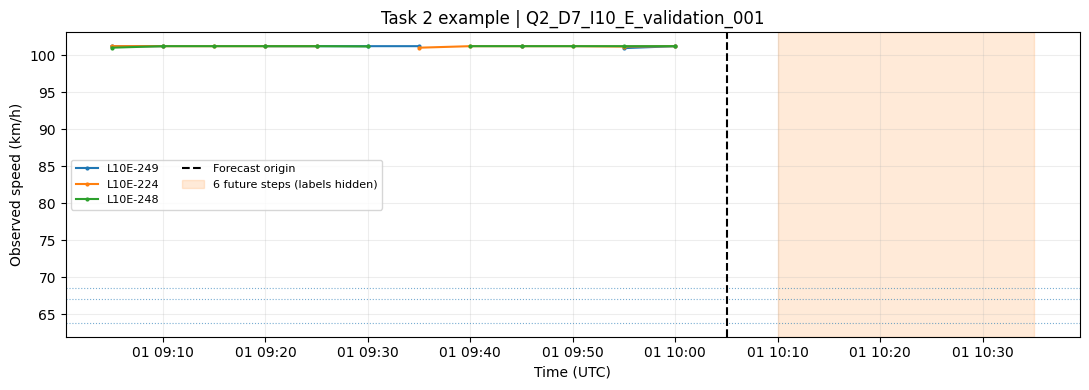

In [15]:
q_links = pl.read_csv(DATA / "corridors" / QUEUE_PANEL / "network" / "links.csv")
h = (history.filter(pl.col("window_id") == wid)
     .join(q_links.select("link_id", "free_speed_kmh"), on="link_id", how="left"))
chosen = (h.group_by("link_id").agg(pl.col("speed_kmh").min().alias("min_speed"))
          .sort("min_speed").head(3)["link_id"].to_list())
fig, ax = plt.subplots(figsize=(11, 4))
for link in chosen:
    one = h.filter(pl.col("link_id") == link).sort("timestamp")
    x = [datetime.fromisoformat(t.replace("Z", "+00:00")) for t in one["timestamp"]]
    ax.plot(x, one["speed_kmh"].to_numpy(), marker=".", ms=4, label=link)
    ax.axhline(0.6 * one["free_speed_kmh"][0], ls=":", lw=.8, alpha=.6)
origin = datetime.fromisoformat(window["forecast_origin"].replace("Z", "+00:00"))
start = datetime.fromisoformat(window["forecast_start"].replace("Z", "+00:00"))
end = datetime.fromisoformat(window["forecast_end"].replace("Z", "+00:00"))
ax.axvline(origin, color="black", ls="--", label="Forecast origin")
ax.axvspan(start, end, color="tab:orange", alpha=.16, label="6 future steps (labels hidden)")
ax.set(xlabel="Time (UTC)", ylabel="Observed speed (km/h)", title=f"Task 2 example | {wid}")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

### Task 2 구간의 blank도 Task 1 타깃은 아닐 수 있습니다

`history_end`/`forecast_origin` 시각은 이 예제의 공개 이력 12개 시점에 포함되지 않고, 실제 마지막 이력은 그 5분 전입니다. 아래는 같은 날짜의 validation masked 본선에서 적격 blank와 공식 Task 1 타깃 수를 비교합니다. 차이는 별도 예측 구간과 버퍼 등에서 생기므로, **마스킹 파일의 null 여부만으로 타깃을 만들면 안 됩니다.**

In [16]:
example_date = window["date"]
val_mask_root = DATA / "corridors" / QUEUE_PANEL / TASK_SPLIT / "mainline_states_masked"
val_day_file = next(val_mask_root.rglob(f"*{example_date.replace('-', '_')}.parquet"))
val_day = pl.read_parquet(val_day_file)
val_target_file = DATA / "task1" / QUEUE_PANEL / TASK_SPLIT / "sample_submission_state.csv"
val_targets = (pl.scan_csv(val_target_file)
               .filter(pl.col("timestamp").str.starts_with(example_date))
               .select(JOIN).collect())
eligible_blank = val_day.filter((pl.col("is_score_eligible") == 1) & pl.col("speed_kmh").is_null())
non_target_blank = eligible_blank.join(val_targets, on=JOIN, how="anti")
display(pl.DataFrame([{"panel": QUEUE_PANEL, "date": example_date,
                       "eligible_blank": eligible_blank.height,
                       "task1_target": val_targets.height,
                       "eligible_blank_not_target": non_target_blank.height}]))
print(f"{example_date}: 적격 blank {eligible_blank.height:,}개 중 {non_target_blank.height:,}개는 Task 1 타깃이 아닙니다.")

panel,date,eligible_blank,task1_target,eligible_blank_not_target
str,str,i64,i64,i64
"""D7_I10_E""","""2031-03-01""",16788,14741,2047


2031-03-01: 적격 blank 16,788개 중 2,047개는 Task 1 타깃이 아닙니다.


## 6. Task 4 — 경로 유량과 링크 카운트

`path_set.csv`는 출발·도착 zone과 경로를, `path_link_incidence.csv`는 경로가 지나가는 링크를 나타냅니다. `synthetic_weak_prior.csv`는 초기 경로 유량이며 정답이 아닙니다. `synthetic_link_counts.csv`는 링크별 관측 제약입니다. 여러 경로가 같은 링크를 지나므로 경로 유량을 합치면 그 링크의 **prior 예상 유량**을 만들 수 있습니다. 둘의 차이가 추정 문제의 출발점입니다.

이 릴리스의 `departure_time`은 아래처럼 `SYN_PM_VALIDATION` 같은 합성 시나리오 식별자일 수 있으며, 5분 timestamp로 해석하면 안 됩니다.

In [17]:
task4_dir = DATA / "task4" / PANEL / TASK_SPLIT
paths = pl.read_csv(network / "path_set.csv")
incidence = pl.read_csv(network / "path_link_incidence.csv")
weak_prior = pl.read_csv(task4_dir / "synthetic_weak_prior.csv")
link_counts = pl.read_csv(task4_dir / "synthetic_link_counts.csv")
path_template = pl.read_csv(task4_dir / "sample_submission_path_flow.csv")
print("Network links:", links.height, "| paths:", paths.height, "| path-link pairs:", incidence.height)
print("Weak prior rows:", weak_prior.height, "| released link counts:", link_counts.height,
      "| Task 4 target rows:", path_template.height)
display(paths.select("path_id", "origin_zone", "destination_zone", "link_seq").head(4))
display(weak_prior.head(4))
display(link_counts.head(4))

Network links: 146 | paths: 4278 | path-link pairs: 423219
Weak prior rows: 4278 | released link counts: 137 | Task 4 target rows: 4278


path_id,origin_zone,destination_zone,link_seq
str,str,str,str
"""P000_001""","""Z0""","""Z1""","""L10E-166"""
"""P000_002""","""Z0""","""Z2""","""L10E-166;L10E-147"""
"""P000_003""","""Z0""","""Z3""","""L10E-166;L10E-147;L10E-209;L10…"
"""P000_004""","""Z0""","""Z4""","""L10E-166;L10E-147;L10E-209;L10…"


panel,departure_time,path_id,origin_zone,destination_zone,path_flow
str,str,str,str,str,f64
"""D7_I10_E""","""SYN_PM_VALIDATION""","""P000_001""","""Z0""","""Z1""",412.236121
"""D7_I10_E""","""SYN_PM_VALIDATION""","""P000_002""","""Z0""","""Z2""",346.234884
"""D7_I10_E""","""SYN_PM_VALIDATION""","""P000_003""","""Z0""","""Z3""",76.670517
"""D7_I10_E""","""SYN_PM_VALIDATION""","""P000_004""","""Z0""","""Z4""",83.631328


panel,link_id,count
str,str,f64
"""D7_I10_E""","""L10E-166""",3390.491917
"""D7_I10_E""","""L10E-147""",5104.100918
"""D7_I10_E""","""L10E-043""",5098.335435
"""D7_I10_E""","""L10E-171""",5098.335435


link_id,prior_implied_flow,count
str,f64,f64
"""L10E-008""",13851.515555,5133.15157
"""L10E-258""",8021.172463,5226.170978
"""L10E-078""",10997.442812,5310.272105
"""L10E-164""",9038.932131,5058.834396
"""L10E-057""",6633.439155,5016.104722


Links shared by incidence and count file: 137


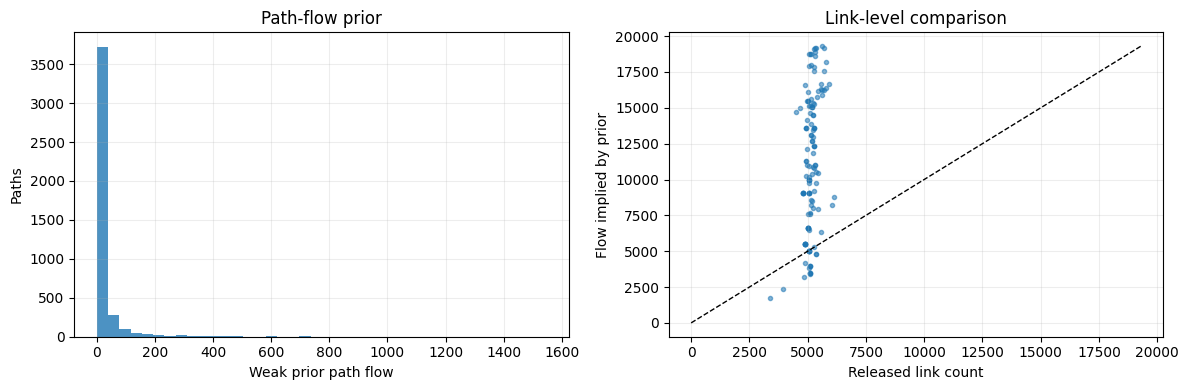

In [18]:
prior_by_link = (
    weak_prior.select("path_id", "path_flow")
    .join(incidence, on="path_id", how="inner")
    .group_by("link_id").agg(pl.col("path_flow").sum().alias("prior_implied_flow"))
    .join(link_counts.select("link_id", "count"), on="link_id", how="inner")
)
display(prior_by_link.head(5))
print("Links shared by incidence and count file:", prior_by_link.height)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(weak_prior["path_flow"].to_numpy(), bins=40, color="tab:blue", alpha=.8)
axes[0].set(xlabel="Weak prior path flow", ylabel="Paths", title="Path-flow prior")
axes[1].scatter(prior_by_link["count"].to_numpy(), prior_by_link["prior_implied_flow"].to_numpy(), s=9, alpha=.55)
lim = max(prior_by_link["count"].max(), prior_by_link["prior_implied_flow"].max())
axes[1].plot([0, lim], [0, lim], ls="--", color="black", lw=1)
axes[1].set(xlabel="Released link count", ylabel="Flow implied by prior", title="Link-level comparison")
plt.tight_layout(); plt.show()

## 기본 설정(`D7_I10_E`)에서 확인한 사실

- Train 예시일 `2030-06-03`에는 본선 42,048셀 중 품질 기준을 통과한 셀이 32,048개입니다. 원본 속도가 빈 셀은 7,023개이고, 별도의 Task 1 복원 타깃은 5,662개입니다.
- 레짐별 하루 표본에서 적격 셀의 가림 비율은 R1 17.7%, R2 27.1%, R3 49.8%였습니다. R3에서 시간·공간 단서가 더 많이 사라집니다.
- Validation 예시일 `2031-03-01`에는 적격 blank 16,788개 중 공식 Task 1 타깃이 14,741개입니다. **2,047개는 blank여도 Task 1 타깃이 아닙니다.**
- Train 첫 주 평균은 오후 UTC 시간대에 속도가 낮고 차로당 유량이 높습니다. 이는 이 패널·이 기간의 탐색 결과이며 다른 패널·월에도 그대로 적용된다고 가정하면 안 됩니다.
- Task 4의 약한 prior를 링크별로 더한 값은 공개 링크 카운트와 눈에 띄게 다릅니다. prior는 정답표가 아니라 추정을 시작할 때 쓰는 입력입니다.

## 7. 다음 분석을 위한 체크리스트

1. **Task 1**: train의 `mainline_states_masked`로 예측하고 `mainline_states`로 평가합니다. 타깃은 반드시 `task1/.../sample_submission_state.csv`에서 고릅니다. R1/R2/R3 각각을 확인합니다.
2. **Task 2**: 8개 패널에만 window가 있습니다. 이력 60분과 예측 6스텝을 분리합니다. 미래 라벨은 공개되지 않습니다.
3. **Task 3**: 별도 제출 행은 없습니다. 본선 상태의 속도·유량을 함께 개선해야 합니다. 물리 density는 `q/v`입니다. 품질이 낮은 ramp는 0으로 바꾸지 않습니다.
4. **Task 4**: 경로–링크 매핑과 약한 prior를 링크 카운트에 맞추되, 기준 path flow는 비공개입니다.
5. **제출**: `sample_submission.csv`의 모든 ID를 채우고, `submission_key.csv`는 매핑에만 사용합니다. validation/private 입력을 읽을 수 있지만 숨겨진 정답은 없습니다.

**바꿔 보기**: 맨 위 `PANEL`을 다른 방향으로 바꿔 실행하면 동일한 분석을 할 수 있습니다. Task 2가 없는 D12_I405 방향을 고르면 Task 2 예시는 `D7_I10_E`로 자동 전환됩니다.